# **Project Name**    -  PhonePe Transaction Insights

##### **Project Type**    - EDA
##### **Contribution**    - Individual
##### **Team Member 1 -** <Your Name>

# **Project Summary -**

India's digital payments boom is one of the largest behavioural shifts in modern finance, and PhonePe sits at the centre of it. This project analyses the open PhonePe Pulse dataset to understand how transactions, registered users and merchants have grown across 36 states and union territories, and to turn that understanding into decisions about marketing, product and risk. The data covers every quarter from Q1 2018 to Q2 2026 and is organised in nine tables (aggregated, map and top views of transactions, users and merchants). The project brief mentions insurance data and pin codes; the current Pulse release contains neither, so merchant data replaces insurance and district is the finest geography.

The pipeline has five stages. First, about 11,000 JSON files were parsed with Python into clean tables, and state totals reconciled to the country totals with zero difference. Second, the tables were loaded into PostgreSQL with primary keys, check constraints and indexes. Third, fifteen business queries covering segmentation, geography, payment performance, trends, engagement, merchants and anomaly screening were written and timed; most run in under 15 milliseconds. Fourth, this notebook explores the data through 21 charts following the Univariate, Bivariate and Multivariate structure. Fifth, results were packaged as a Streamlit dashboard and as a static web dashboard built for Vercel.

The headline findings are as follows. Volume is enormous and still compounding: 128.5B transactions worth about ₹155 lakh crore were processed in 2025, and quarterly volume rose from 140.0M in Q1 2018 to 38.7B in Q2 2026. Growth is slowing in percentage terms, as expected for a maturing market, with year-on-year growth in 2025 of 34.0% for retail, 23.9% for person-to-person transfers and 15.5% for utility payments. The mix has shifted decisively towards commerce: retail rose from 49.3% of transactions in 2018 to 61.9% in 2025, while peer transfers fell from 47.3% to 32.0%.

Activity is concentrated. The five largest states account for 52.3% of 2025 transactions, led by Maharashtra and Karnataka, and fifteen districts generate 21.7% of national value. Yet engagement per user varies sharply: Telangana (106), Andhra Pradesh (95), Karnataka (85) lead on transactions per registered user, whereas Manipur (12), Mizoram (13), Kerala (18) trail far behind. Registered users and transactions move almost in lockstep across states (log-log correlation 0.98), so the interesting question is not where the users are but which of them are active.

District segmentation using median cut-offs for frequency and ticket size produced four groups. Everyday spenders contribute 45.4% of value and power hubs 35.4%, while 181 emerging districts hold 134.9M registered users who transact far less often. Kerala is a cautionary case: it ranks 36 of 36 on three-year growth and sits well below the national engagement average.

The recommendations are to protect and deepen the retail and merchant franchise in the top states, run activation campaigns in large but under-engaged districts, invest in merchant acquisition where density is lowest, and investigate Kerala's slowdown. A screening query also flags districts with unusual average ticket sizes for review by risk teams; these flags are signals, not proof of fraud. All code, SQL, dashboards and documentation are version controlled so the analysis can be reproduced end to end.

# **GitHub Link -**

https://github.com/<your-username>/phonepe-transaction-insights  *(replace with your repository link)*

# **Problem Statement**

**Digital payments generate rich data, but without structured analysis it is hard to know where PhonePe is strong, where it is under-penetrated and what is changing. This project analyses PhonePe Pulse data to explain payment-category performance, user and merchant growth, and state and district level differences, and to recommend where to act.**

#### **Define Your Business Objective?**

Use transaction, user and merchant data to (1) find which states, districts and payment categories drive volume and value, (2) separate large-but-inactive user bases from genuinely engaged ones, (3) spot growth slowdowns early, and (4) give marketing, product and risk teams a prioritised list of actions.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
VIOLET, SAFFRON, LILAC, RED, INK = "#5F259F", "#E8A33D", "#9B6BD0", "#C8453B", "#1B1630"
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 30

### Dataset Loading

In [2]:
TABLES = ["aggregated_transaction", "aggregated_user", "aggregated_merchant",
          "map_transaction", "map_user", "map_merchant",
          "top_transaction", "top_user", "top_merchant"]

def find_csv_dir():
    """Locate data/processed whether run from notebook/, repo root, or Colab."""
    for p in [Path("../data/processed"), Path("data/processed"), Path("/content/data/processed"),
              Path("/content/phonepe-transaction-insights/data/processed")]:
        if all((p / f"{t}.csv").exists() for t in TABLES):
            return p
    raise FileNotFoundError("data/processed/*.csv not found. Run data_extraction/extract_pulse.py "
                            "or clone the repo so the data/processed folder is next to this notebook.")

def load_tables():
    """PostgreSQL if DATABASE_URL is set (postgresql+psycopg2://user:pw@host/phonepe), else CSVs."""
    url = os.getenv("DATABASE_URL")
    if url:
        try:
            from sqlalchemy import create_engine
            eng = create_engine(url)
            return {t: pd.read_sql(f"SELECT * FROM {t}", eng) for t in TABLES}, "PostgreSQL"
        except Exception as exc:                       # never fail the notebook on a DB problem
            print(f"Database unavailable ({type(exc).__name__}); falling back to CSV files.")
    d = find_csv_dir()
    return {t: pd.read_csv(d / f"{t}.csv") for t in TABLES}, f"CSV ({d})"

T, SOURCE = load_tables()
print("Loaded", len(T), "tables from", SOURCE)

Loaded 9 tables from CSV (../data/processed)


### Dataset First View

In [3]:
# Dataset First Look: the three core tables (the other six share the same structure)
for name in ["aggregated_transaction", "map_transaction", "aggregated_user"]:
    print(f"--- {name}")
    display(T[name].head())

--- aggregated_transaction


,state,year,quarter,payment_category,txn_count
0,Andaman & Nicobar Islands,2018,1,P2P,2297
1,Andaman & Nicobar Islands,2018,1,Retail,6656
2,Andaman & Nicobar Islands,2018,1,Utility,136
3,Andaman & Nicobar Islands,2018,2,P2P,4383
4,Andaman & Nicobar Islands,2018,2,Retail,10462


--- map_transaction


,state,year,quarter,district,txn_count,txn_amount
0,Andaman & Nicobar Islands,2018,1,Nicobar,696,"1,455,284.39"
1,Andaman & Nicobar Islands,2018,1,North And Middle Andaman,537,"1,150,313.29"
2,Andaman & Nicobar Islands,2018,1,South Andaman,7856,"15,963,528.53"
3,Andaman & Nicobar Islands,2018,2,North And Middle Andaman,1077,"1,601,668.68"
4,Andaman & Nicobar Islands,2018,2,South Andaman,12505,"30,134,503.88"


--- aggregated_user


,state,year,quarter,registered_users
0,Andaman & Nicobar Islands,2018,1,9292
1,Andaman & Nicobar Islands,2018,2,12739
2,Andaman & Nicobar Islands,2018,3,15949
3,Andaman & Nicobar Islands,2018,4,20050
4,Andaman & Nicobar Islands,2019,1,24369


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count for all nine tables
pd.DataFrame({t: {"rows": df.shape[0], "columns": df.shape[1]} for t, df in T.items()}).T

,rows,columns
aggregated_transaction,3671,5
aggregated_user,1224,4
aggregated_merchant,1178,4
map_transaction,26616,6
map_user,26622,5
map_merchant,24737,5
top_transaction,10540,7
top_user,10540,7
top_merchant,10072,7


### Dataset Information

In [5]:
# Dataset Info: dtypes and memory for each table
for name in ["aggregated_transaction", "map_transaction"]:
    print(f"--- {name}"); T[name].info()
pd.DataFrame({t: df.dtypes.astype(str).value_counts() for t, df in T.items()}).fillna(0).astype(int).T

--- aggregated_transaction
<class 'pandas.DataFrame'>
RangeIndex: 3671 entries, 0 to 3670
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   state             3671 non-null   str  
 1   year              3671 non-null   int64
 2   quarter           3671 non-null   int64
 3   payment_category  3671 non-null   str  
 4   txn_count         3671 non-null   int64
dtypes: int64(3), str(2)
memory usage: 199.5 KB
--- map_transaction
<class 'pandas.DataFrame'>
RangeIndex: 26616 entries, 0 to 26615
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   state       26616 non-null  str    
 1   year        26616 non-null  int64  
 2   quarter     26616 non-null  int64  
 3   district    26616 non-null  str    
 4   txn_count   26616 non-null  int64  
 5   txn_amount  26616 non-null  float64
dtypes: float64(1), int64(3), str(2)
memory usage: 1.7 MB


,float64,int64,str
aggregated_transaction,0,3,2
aggregated_user,0,3,1
aggregated_merchant,0,3,1
map_transaction,1,3,2
map_user,0,3,2
map_merchant,0,3,2
top_transaction,0,4,3
top_user,0,4,3
top_merchant,0,4,3


#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
pd.Series({t: int(df.duplicated().sum()) for t, df in T.items()}, name="duplicate rows").to_frame()

,duplicate rows
aggregated_transaction,0
aggregated_user,0
aggregated_merchant,0
map_transaction,0
map_user,0
map_merchant,0
top_transaction,0
top_user,0
top_merchant,0


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
pd.Series({t: int(df.isna().sum().sum()) for t, df in T.items()}, name="null cells").to_frame()

,null cells
aggregated_transaction,0
aggregated_user,0
aggregated_merchant,0
map_transaction,0
map_user,0
map_merchant,0
top_transaction,0
top_user,0
top_merchant,0


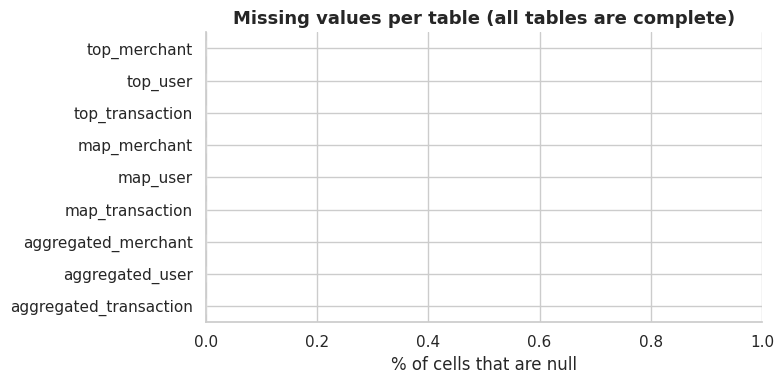

In [8]:
# Visualizing the missing values: share of null cells per table
miss = pd.Series({t: df.isna().mean().mean() * 100 for t, df in T.items()})
ax = miss.sort_values().plot.barh(color=VIOLET, figsize=(8, 4))
ax.set_xlabel("% of cells that are null"); ax.set_xlim(0, 1); ax.set_title("Missing values per table (all tables are complete)")
plt.tight_layout(); plt.show()

### What did you know about your dataset?

The nine tables hold **115,200 rows** in total and are structured as {aggregated, map, top} x {transaction, user, merchant}. Coverage is **36 states and UTs** from **2018 Q1 to 2026 Q2**. There are **no missing values and no duplicate rows**, and district totals match state totals exactly, so no cleaning was needed. Three limitations shape the analysis: transaction **amounts exist only at district level** (`map_transaction`), there is **no insurance or pin-code data** in the current Pulse release (merchant data replaces insurance), and the top tables only list the leading entities rather than all of them.

## ***2. Understanding Your Variables***

In [9]:
# Dataset Columns
{t: list(df.columns) for t, df in T.items()}

{'aggregated_transaction': ['state',
  'year',
  'quarter',
  'payment_category',
  'txn_count'],
 'aggregated_user': ['state', 'year', 'quarter', 'registered_users'],
 'aggregated_merchant': ['state', 'year', 'quarter', 'registered_merchants'],
 'map_transaction': ['state',
  'year',
  'quarter',
  'district',
  'txn_count',
  'txn_amount'],
 'map_user': ['state', 'year', 'quarter', 'district', 'registered_users'],
 'map_merchant': ['state',
  'year',
  'quarter',
  'district',
  'registered_merchants'],
 'top_transaction': ['state',
  'year',
  'quarter',
  'entity_level',
  'rank',
  'entity_name',
  'txn_count'],
 'top_user': ['state',
  'year',
  'quarter',
  'entity_level',
  'rank',
  'entity_name',
  'registered_users'],
 'top_merchant': ['state',
  'year',
  'quarter',
  'entity_level',
  'rank',
  'entity_name',
  'registered_merchants']}

In [10]:
# Dataset Describe
T["map_transaction"].describe().T

,count,mean,std,min,25%,50%,75%,max
year,"26,616.00","2,021.77",2.46,"2,018.00","2,020.00","2,022.00","2,024.00","2,026.00"
quarter,"26,616.00",2.44,1.12,1.00,1.00,2.00,3.00,4.00
txn_count,"26,616.00","16,435,221.77","57,921,021.96",2.00,"379,233.75","2,776,078.00","14,061,256.75","2,113,433,404.00"
txn_amount,"26,616.00","22,064,125,634.43","65,421,565,230.06",57.10,"689,404,129.86","4,822,098,451.79","21,191,250,561.00","2,237,234,966,747.10"


### Variables Description

| Variable | Meaning |
|---|---|
| `state`, `district` | Geography. 36 states/UTs; 783 districts (names cleaned, e.g. "Pune district" becomes "Pune") |
| `year`, `quarter` | Reporting period (calendar quarters) |
| `payment_category` | P2P (person-to-person), Retail (merchant payments) or Utility (bills, recharges) |
| `txn_count` | Number of transactions |
| `txn_amount` | Transaction value in rupees (district level only) |
| `registered_users` | Cumulative registered PhonePe users (a stock, not a flow) |
| `registered_merchants` | Cumulative registered merchants (a stock) |
| `entity_level`, `rank`, `entity_name` | Top tables: ranked states (country file) or districts (state file) |

### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable
for name in ["aggregated_transaction", "map_transaction", "map_user"]:
    print(f"--- {name}")
    print(T[name].nunique().to_string(), "\n")
print("Payment categories:", sorted(T["aggregated_transaction"].payment_category.unique()))

--- aggregated_transaction
state                 36
year                   9
quarter                4
payment_category       3
txn_count           3671 

--- map_transaction
state            36
year              9
quarter           4
district        780
txn_count     26506
txn_amount    26616 

--- map_user
state                  36
year                    9
quarter                 4
district              780
registered_users    26011 

Payment categories: ['P2P', 'Retail', 'Utility']


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
REGION = {
    "North":     ["Delhi", "Haryana", "Himachal Pradesh", "Jammu & Kashmir", "Ladakh", "Punjab", "Chandigarh", "Uttarakhand", "Rajasthan"],
    "Central":   ["Madhya Pradesh", "Chhattisgarh", "Uttar Pradesh"],
    "West":      ["Maharashtra", "Gujarat", "Goa", "Dadra & Nagar Haveli & Daman & Diu"],
    "South":     ["Andhra Pradesh", "Karnataka", "Kerala", "Tamil Nadu", "Telangana", "Puducherry", "Lakshadweep"],
    "East":      ["Bihar", "Jharkhand", "Odisha", "West Bengal", "Andaman & Nicobar Islands"],
    "Northeast": ["Assam", "Arunachal Pradesh", "Manipur", "Meghalaya", "Mizoram", "Nagaland", "Sikkim", "Tripura"],
}
STATE2REGION = {s: r for r, ss in REGION.items() for s in ss}

at, au, am, mt, mu, mm = (T[k].copy() for k in ["aggregated_transaction", "aggregated_user", "aggregated_merchant",
                                                "map_transaction", "map_user", "map_merchant"])
for df in (at, au, am, mt, mu, mm):                      # readable period label on every table
    df["period"] = df.year.astype(str) + " Q" + df.quarter.astype(str)

at["region"] = at.state.map(STATE2REGION)                 # region on the aggregated table too

LY, LQ = (int(v) for v in at.sort_values(["year", "quarter"]).iloc[-1][["year", "quarter"]])   # latest period

# ---- state x quarter panel: one row per state per quarter, every headline metric
tx = (at.pivot_table(index=["state", "year", "quarter"], columns="payment_category", values="txn_count", aggfunc="sum")
        .reset_index())
tx["txns"] = tx[["P2P", "Retail", "Utility"]].sum(axis=1)
amt = mt.groupby(["state", "year", "quarter"], as_index=False).txn_amount.sum()
state_q = (tx.merge(amt, on=["state", "year", "quarter"], how="left")
             .merge(au[["state", "year", "quarter", "registered_users"]], on=["state", "year", "quarter"], how="left")
             .merge(am[["state", "year", "quarter", "registered_merchants"]], on=["state", "year", "quarter"], how="left"))
state_q = state_q.rename(columns={"registered_users": "users", "registered_merchants": "merchants"})
state_q["amount_cr"] = state_q.txn_amount / 1e7                      # 1 crore = 10^7 INR
state_q["ticket"] = state_q.txn_amount / state_q.txns                 # average ticket size (INR)
state_q["txns_per_user"] = state_q.txns / state_q.users
state_q["merchants_per_1k"] = 1000 * state_q.merchants / state_q.users
state_q["region"] = state_q.state.map(STATE2REGION)
state_q["period"] = state_q.year.astype(str) + " Q" + state_q.quarter.astype(str)
state_q["date"] = pd.to_datetime(state_q.year.astype(str) + "-" + (state_q.quarter * 3).astype(str) + "-01") + pd.offsets.MonthEnd(0)   # quarter-end date

# ---- national quarterly series
nat_q = (state_q.groupby(["year", "quarter", "date"], as_index=False)
                .agg(txns=("txns", "sum"), amount_cr=("amount_cr", "sum"), users=("users", "sum")))
nat_q["qoq_pct"] = nat_q.txns.pct_change() * 100
state_latest = state_q[(state_q.year == LY) & (state_q.quarter == LQ)].copy()

# ---- district table for the last full calendar year (2025)
d = mt[mt.year == 2025].groupby(["state", "district"], as_index=False).agg(txns=("txn_count", "sum"), amount=("txn_amount", "sum"))
u = mu[(mu.year == 2025) & (mu.quarter == 4)][["state", "district", "registered_users"]]
m = mm[(mm.year == 2025) & (mm.quarter == 4)][["state", "district", "registered_merchants"]]
dist = d.merge(u, on=["state", "district"], how="inner").merge(m, on=["state", "district"], how="left")
dist = dist[dist.registered_users > 0].copy()
dist["amount_cr"] = dist.amount / 1e7
dist["ticket"] = dist.amount / dist.txns
dist["txns_per_user"] = dist.txns / dist.registered_users
f_med, t_med = dist.txns_per_user.median(), dist.ticket.median()     # median cut for segmentation
def segment(r):
    if r.txns_per_user >= f_med:
        return "Power hubs" if r.ticket >= t_med else "Everyday spenders"
    return "Big-ticket occasional" if r.ticket >= t_med else "Emerging / under-engaged"
dist["segment"] = dist.apply(segment, axis=1)
dist["region"] = dist.state.map(STATE2REGION)

print("state_q:", state_q.shape, "| nat_q:", nat_q.shape, "| dist:", dist.shape, f"| latest period: {LY} Q{LQ}")

state_q: (1224, 17) | nat_q: (34, 7) | dist: (783, 11) | latest period: 2026 Q2


In [13]:
# Sanity checks on the wrangled frames (these fail loudly if the data changes shape)
assert state_q.state.nunique() == 36, "expected 36 states/UTs"
assert state_q.region.notna().all(), "every state must map to a region"
assert (state_q.txns > 0).all() and state_q.txn_amount.notna().all()
recon = at.groupby(["state", "year", "quarter"]).txn_count.sum().sum() - mt.groupby(["state", "year", "quarter"]).txn_count.sum().sum()
print("Aggregated vs district-level transaction totals differ by:", int(recon))
state_q.head()

Aggregated vs district-level transaction totals differ by: 0


,state,year,quarter,P2P,Retail,Utility,txns,txn_amount,users,merchants,amount_cr,ticket,txns_per_user,merchants_per_1k,region,period,date
0,Andaman & Nicobar Islands,2018,1,"2,297.00","6,656.00",136.00,"9,089.00","18,569,126.20",9292,NaN,1.86,"2,043.03",0.98,NaN,East,2018 Q1,2018-03-31
1,Andaman & Nicobar Islands,2018,2,"4,383.00","10,462.00",217.00,"15,062.00","35,517,275.86",12739,NaN,3.55,"2,358.07",1.18,NaN,East,2018 Q2,2018-06-30
2,Andaman & Nicobar Islands,2018,3,"7,608.00","13,138.00",408.00,"21,154.00","67,343,424.71",15949,NaN,6.73,"3,183.48",1.33,NaN,East,2018 Q3,2018-09-30
3,Andaman & Nicobar Islands,2018,4,"12,260.00","18,359.00",520.00,"31,139.00","107,983,057.52",20050,NaN,10.80,"3,467.78",1.55,NaN,East,2018 Q4,2018-12-31
4,Andaman & Nicobar Islands,2019,1,"15,423.00","24,638.00",665.00,"40,726.00","126,352,730.02",24369,5.00,12.64,"3,102.51",1.67,0.21,East,2019 Q1,2019-03-31


### What all manipulations have you done and insights you found?

1. **Standardised names**: state slugs and district strings were cleaned during extraction, which made all 36 states join cleanly across tables.
2. **Built a state x quarter panel** (`state_q`) joining transactions (by category), value, registered users and merchants, plus derived metrics: average ticket size (value / count), transactions per user and merchants per 1,000 users.
3. **Added a `region` column** (North, Central, West, South, East, Northeast) to enable regional comparisons.
4. **Built a district table for 2025** (`dist`) joining value, year-end users and merchants, and assigned each district to a segment using median frequency and median ticket.
5. **Kept only full calendar years (<= 2025) for growth rates**, because 2026 holds just two quarters.

Insight: the district totals reconcile to the state totals with **zero** difference, so any gap between charts is a modelling choice, not a data error.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

### Univariate analysis

#### Chart - 1  (U - distribution of state-quarter transaction volume)

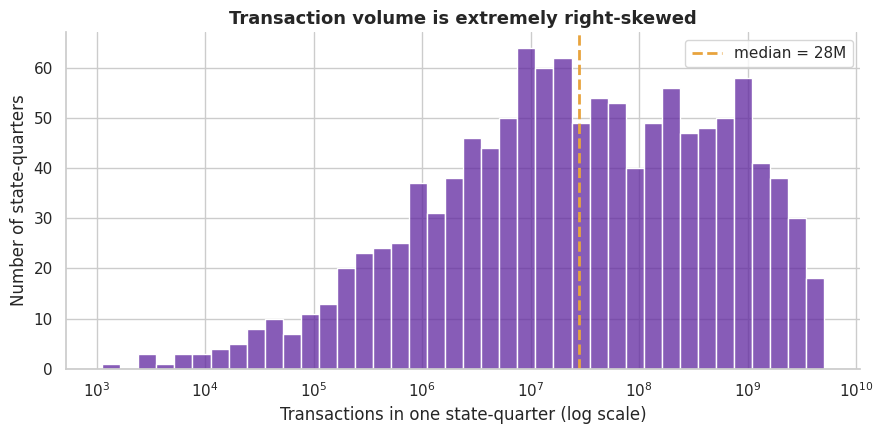

In [14]:
# Chart - 1 visualization code
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(state_q.txns, bins=40, log_scale=True, color=VIOLET, ax=ax)
ax.axvline(state_q.txns.median(), color=SAFFRON, lw=2, ls="--", label=f"median = {state_q.txns.median()/1e6:,.0f}M")
ax.set(xlabel="Transactions in one state-quarter (log scale)", ylabel="Number of state-quarters", title="Transaction volume is extremely right-skewed")
ax.legend(); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A histogram shows the shape of a single numeric variable, and a log axis is needed because volumes span several orders of magnitude.

##### 2. What is/are the insight(s) found from the chart?

The median state-quarter processes **27.7M** transactions but the largest reaches **5.1B**, about **183x** the median. The distribution is heavily right-skewed because most observations are small or early-period states while a few large states in recent quarters dominate.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** averages would mislead planning here, so teams should use medians and segment by size. **Risk:** the long tail means a few states carry the business; a disruption in one of them has an outsized revenue impact.

#### Chart - 2  (U - payment category mix)

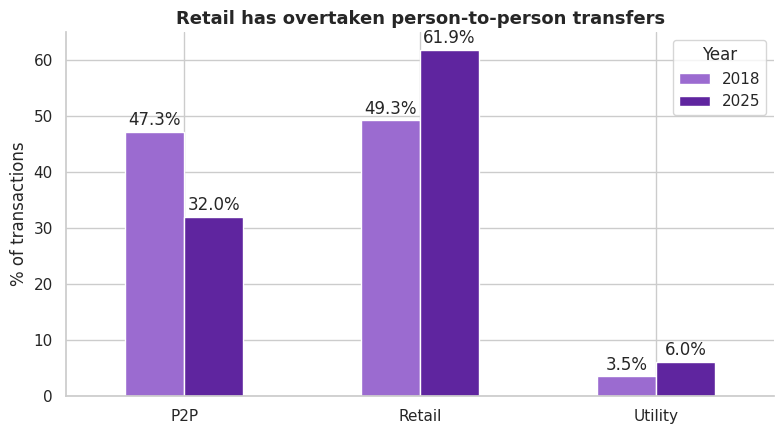

In [15]:
# Chart - 2 visualization code
cat = at[at.year.isin([2018, 2025])].groupby(["year", "payment_category"]).txn_count.sum().unstack()
cat = cat.div(cat.sum(axis=1), axis=0) * 100
ax = cat.T.plot.bar(figsize=(8, 4.5), color=[LILAC, VIOLET], rot=0)
for c in ax.containers: ax.bar_label(c, fmt="%.1f%%", padding=2)
ax.set(xlabel="", ylabel="% of transactions", title="Retail has overtaken person-to-person transfers"); ax.legend(title="Year")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A grouped bar chart compares the share of three categories in two years side by side, which makes the shift easy to read.

##### 2. What is/are the insight(s) found from the chart?

Retail grew from **49.3%** of transactions in 2018 to **61.9%** in 2025, P2P fell from **47.3%** to **32.0%**, and utility rose from **3.5%** to **6.0%**.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the platform is becoming a commerce tool, which supports merchant-fee, lending and offers products. **Risk:** P2P transfers are the main way new users join; a falling share could mean slower organic referral if it continues.

#### Chart - 3  (U - distribution of district average ticket size)

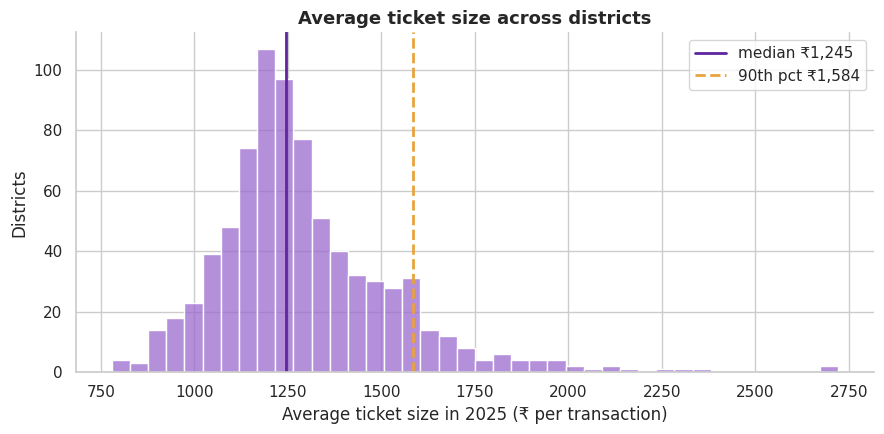

In [16]:
# Chart - 3 visualization code
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(dist.ticket, bins=40, color=LILAC, ax=ax)
ax.axvline(dist.ticket.median(), color=VIOLET, lw=2, label=f"median ₹{dist.ticket.median():,.0f}")
ax.axvline(dist.ticket.quantile(.9), color=SAFFRON, lw=2, ls="--", label=f"90th pct ₹{dist.ticket.quantile(.9):,.0f}")
ax.set(xlabel="Average ticket size in 2025 (₹ per transaction)", ylabel="Districts", title="Average ticket size across districts")
ax.legend(); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Ticket size is a continuous variable, so a histogram with reference lines shows both the typical value and the outlier tail.

##### 2. What is/are the insight(s) found from the chart?

Across **783** districts the median average ticket is **₹1,245**, the 90th percentile **₹1,584** and the maximum **₹2,721**. The spread is moderate overall, with a thin right tail of high-ticket districts.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a stable typical ticket makes revenue forecasting easier and the tail identifies premium districts. **Risk:** the extreme right tail is where unusual behaviour (including fraud) hides, which is why the SQL anomaly query screens it.

#### Chart - 4  (U - registered users of the ten largest states)

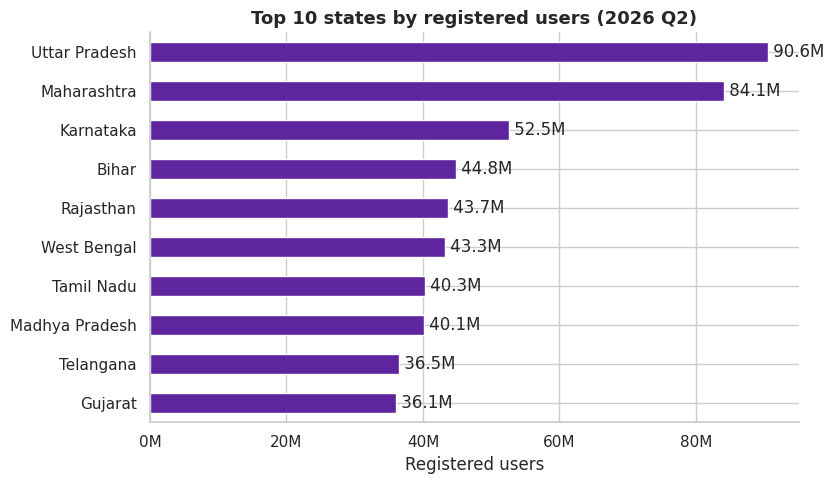

In [17]:
# Chart - 4 visualization code
top = state_latest.nlargest(10, "users").sort_values("users")
ax = top.plot.barh(x="state", y="users", color=VIOLET, figsize=(8.5, 5), legend=False)
for i, v in enumerate(top.users): ax.text(v, i, f" {v/1e6:,.1f}M", va="center")
ax.set(xlabel="Registered users", ylabel="", title=f"Top 10 states by registered users ({LY} Q{LQ})")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e6:,.0f}M")); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A ranked horizontal bar chart is the clearest way to compare one metric across many named categories.

##### 2. What is/are the insight(s) found from the chart?

The five largest states hold **44.4%** of all registered users, led by **Uttar Pradesh** with **90.6M**.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a clear list of anchor markets for brand and retention spend. **Risk:** users are a stock that includes inactive accounts, so this chart overstates the active base; the engagement charts below correct for that.

#### Chart - 5  (U - transactions per registered user across districts)

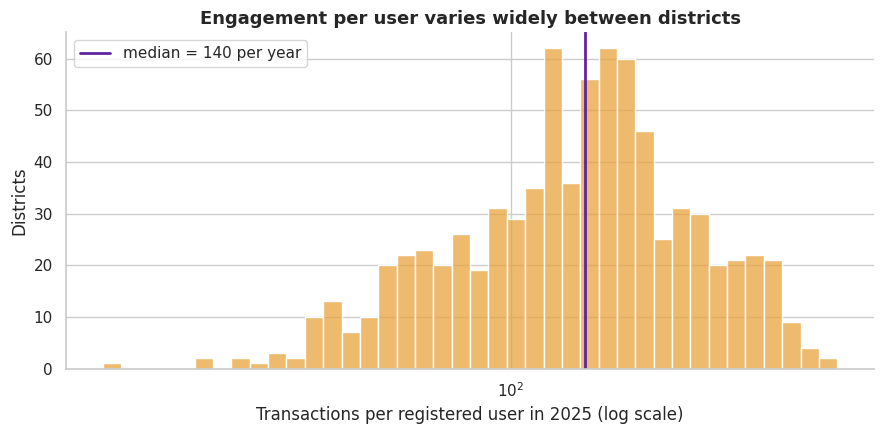

In [18]:
# Chart - 5 visualization code
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(dist.txns_per_user, bins=40, log_scale=True, color=SAFFRON, ax=ax)
ax.axvline(dist.txns_per_user.median(), color=VIOLET, lw=2, label=f"median = {dist.txns_per_user.median():,.0f} per year")
ax.set(xlabel="Transactions per registered user in 2025 (log scale)", ylabel="Districts", title="Engagement per user varies widely between districts")
ax.legend(); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Engagement is the key quality measure; a histogram on a log axis shows how unevenly it is spread.

##### 2. What is/are the insight(s) found from the chart?

The median district sees **140** transactions per user per year, but the 10th percentile is **62** and the 90th is **267**, a gap of about **4.3x**.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the weakest decile has the most room to grow without acquiring a single new user. **Risk:** districts at the left of the chart hold registrations that earn almost no transaction revenue.

### Bivariate analysis

#### Chart - 6  (B - national quarterly transactions (time x numeric))

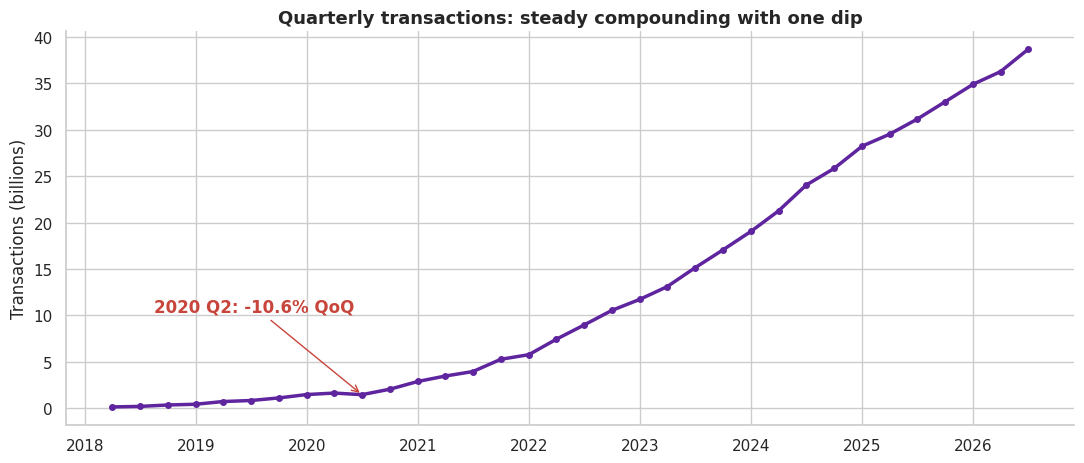

In [19]:
# Chart - 6 visualization code
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(nat_q.date, nat_q.txns / 1e9, color=VIOLET, lw=2.5, marker="o", ms=4)
dip = nat_q[(nat_q.year == 2020) & (nat_q.quarter == 2)].iloc[0]
ax.annotate(f"2020 Q2: {dip.qoq_pct:.1f}% QoQ", (dip.date, dip.txns / 1e9), xytext=(-150, 60), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color=RED), color=RED, fontweight="bold")
ax.set(ylabel="Transactions (billions)", title="Quarterly transactions: steady compounding with one dip"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A line chart is the standard way to show a measure over time and exposes trend, seasonality and breaks.

##### 2. What is/are the insight(s) found from the chart?

Quarterly volume grew from **140.0M** in Q1 2018 to **38.7B** in Q2 2026. The only quarter-on-quarter decline in the whole series is 2020 Q2 (**-10.6%**), which coincides with the national COVID-19 lockdown, followed by a quick rebound.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the platform proved resilient to a shock, which is reassuring for planning. **Risk:** an event like this still removes a quarter of growth, so stress-test forecasts for a downside quarter.

#### Chart - 7  (B - YoY growth by payment category (category x numeric))

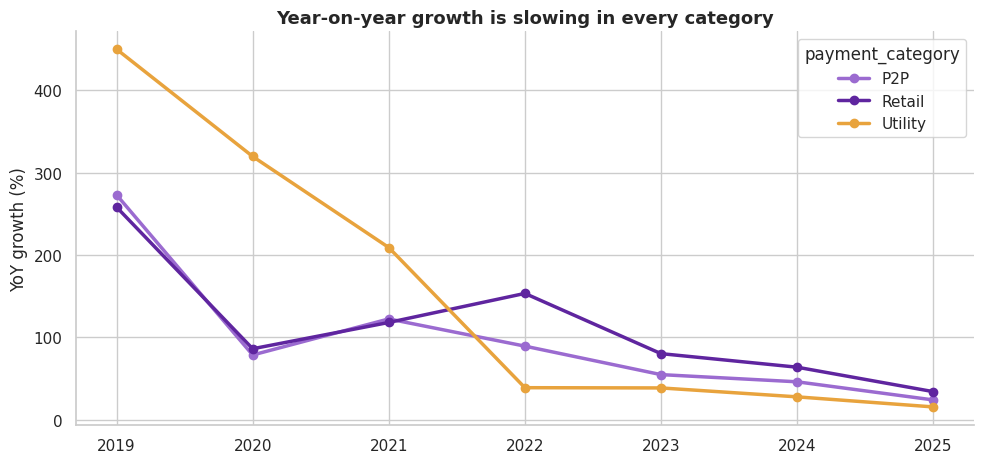

In [20]:
# Chart - 7 visualization code
yearly = at[at.year <= 2025].groupby(["year", "payment_category"]).txn_count.sum().unstack()
growth = yearly.pct_change().loc[2019:] * 100
ax = growth.plot(figsize=(10, 4.8), marker="o", lw=2.5, color={"P2P": LILAC, "Retail": VIOLET, "Utility": SAFFRON})
ax.set(xlabel="", ylabel="YoY growth (%)", title="Year-on-year growth is slowing in every category"); ax.set_xticks(growth.index)
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Multiple lines let us compare growth rates across categories on one axis.

##### 2. What is/are the insight(s) found from the chart?

In 2025, retail grew **34.0%**, P2P **23.9%** and utility **15.5%**, compared with **153.4%**, **89.3%** and **38.8%** in 2022. Growth is decelerating everywhere, but retail stays the fastest.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** retail is still growing at roughly a third a year. **Negative:** the deceleration is a sign of market maturity, so volume targets based on past growth rates will be missed; revenue per transaction will matter more than volume.

#### Chart - 8  (B - top 10 states by 2025 transactions (category x numeric))

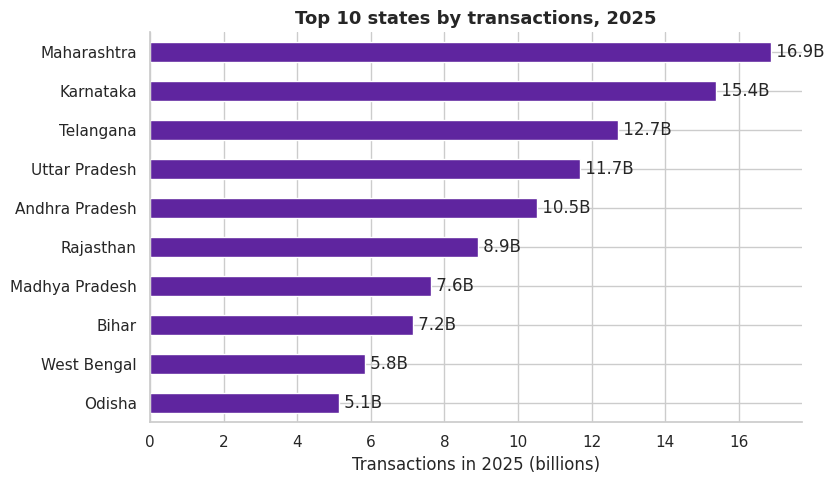

In [21]:
# Chart - 8 visualization code
top = state_q[state_q.year == 2025].groupby("state").txns.sum().nlargest(10).sort_values()
ax = (top / 1e9).plot.barh(color=VIOLET, figsize=(8.5, 5))
for i, v in enumerate(top / 1e9): ax.text(v, i, f" {v:,.1f}B", va="center")
ax.set(xlabel="Transactions in 2025 (billions)", ylabel="", title="Top 10 states by transactions, 2025"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A sorted bar chart ranks states on one numeric measure and makes concentration obvious.

##### 2. What is/are the insight(s) found from the chart?

**Maharashtra** leads with **13.1%** of national volume, followed by **Karnataka**; the top five states together carry **52.3%**.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the strongest markets are the right place to test premium features first. **Risk:** over-reliance on five states; the remaining 31 together make up under half of volume, which is both a risk and a growth pool.

#### Chart - 9  (B - average ticket size by state, top and bottom 8 (category x numeric))

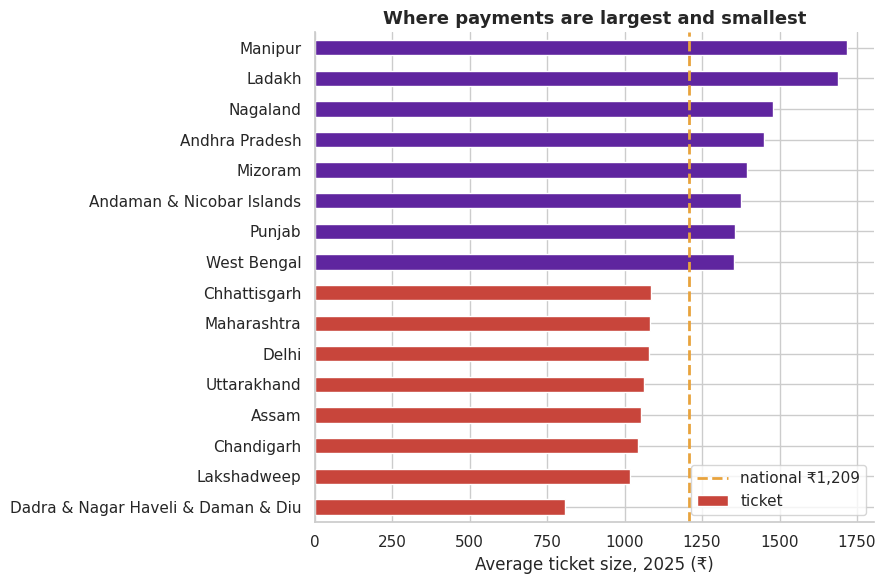

In [22]:
# Chart - 9 visualization code
tk = state_q[state_q.year == 2025].groupby("state").agg(a=("txn_amount", "sum"), t=("txns", "sum"))
tk["ticket"] = tk.a / tk.t; nat_t = tk.a.sum() / tk.t.sum()
sel = pd.concat([tk.nsmallest(8, "ticket"), tk.nlargest(8, "ticket")]).sort_values("ticket")
colors = [RED if v < nat_t else VIOLET for v in sel.ticket]
ax = sel.ticket.plot.barh(color=colors, figsize=(9, 6))
ax.axvline(nat_t, color=SAFFRON, lw=2, ls="--", label=f"national ₹{nat_t:,.0f}")
ax.set(xlabel="Average ticket size, 2025 (₹)", ylabel="", title="Where payments are largest and smallest"); ax.legend(); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A diverging-style bar with a national reference line shows which states sit above or below the benchmark.

##### 2. What is/are the insight(s) found from the chart?

Ticket size ranges from **₹808** in Dadra & Nagar Haveli & Daman & Diu to **₹1,719** in Manipur, against a national average of **₹1,209**. Small and remote states show the highest tickets, large states cluster near the middle.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** high-ticket states suit credit, insurance and investment cross-sell. **Risk:** very low-ticket regions earn less per transaction, so they need volume or merchant-side monetisation to be profitable.

#### Chart - 10  (B - registered users vs transactions by state (numeric x numeric))

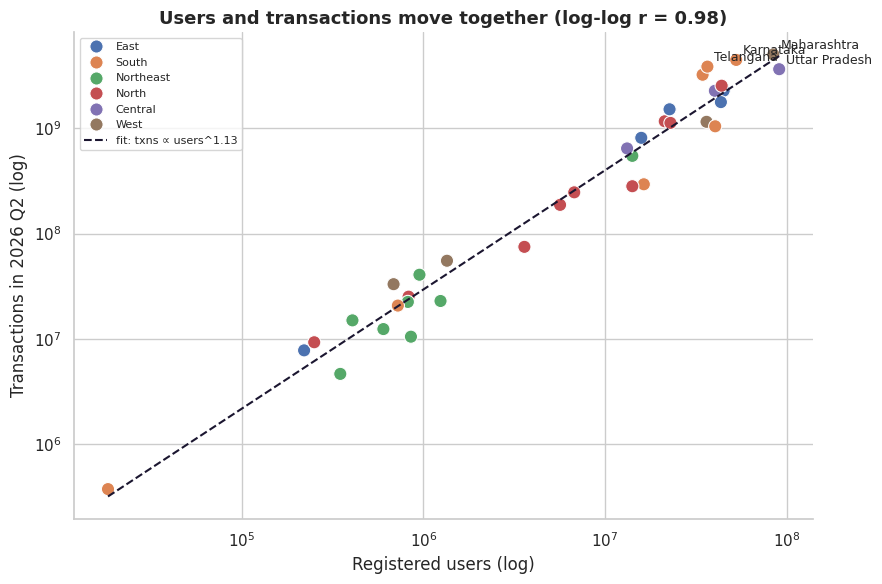

In [23]:
# Chart - 10 visualization code
sl = state_latest.dropna(subset=["users", "txns"])
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=sl, x="users", y="txns", hue="region", s=90, ax=ax)
b, a = np.polyfit(np.log(sl.users), np.log(sl.txns), 1)                 # fit in log space = power law
xs = np.logspace(np.log10(sl.users.min()), np.log10(sl.users.max()), 50)
ax.plot(xs, np.exp(a + b * np.log(xs)), color=INK, lw=1.5, ls="--", label=f"fit: txns ∝ users^{b:.2f}")
ax.set_xscale("log"); ax.set_yscale("log"); ax.legend(fontsize=8)
r = np.corrcoef(np.log(sl.users), np.log(sl.txns))[0, 1]
for _, s in sl.nlargest(4, "txns").iterrows(): ax.annotate(s.state, (s.users, s.txns), xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.set(xlabel="Registered users (log)", ylabel=f"Transactions in {LY} Q{LQ} (log)", title=f"Users and transactions move together (log-log r = {r:.2f})")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A log-log scatter shows the relationship between two numeric variables whose values span orders of magnitude, and a fitted line makes departures visible.

##### 2. What is/are the insight(s) found from the chart?

The log-log correlation is **0.98**, so users explain almost all differences in volume. States **above** the line (more transactions than their user base predicts) include Telangana, Andhra Pradesh, Dadra & Nagar Haveli & Daman & Diu; states **below** it include Kerala, Manipur, Punjab.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** user growth reliably converts to volume, so acquisition is not wasted. **Negative:** states below the line have users who transact less than peers, which is the most direct activation opportunity.

#### Chart - 11  (B - registered users vs merchants by state (numeric x numeric))

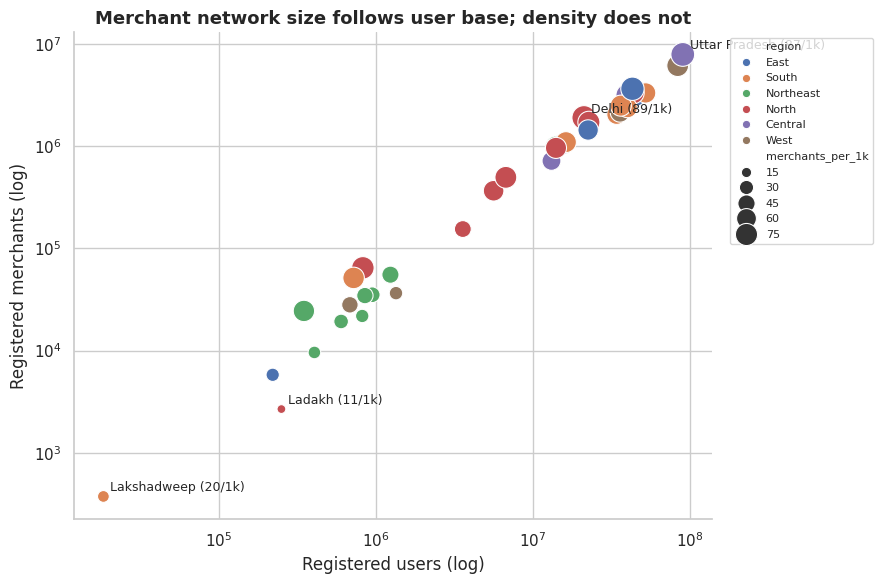

In [24]:
# Chart - 11 visualization code
slm = state_latest.dropna(subset=["users", "merchants"])
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=slm, x="users", y="merchants", hue="region", size="merchants_per_1k", sizes=(40, 300), ax=ax)
ax.set_xscale("log"); ax.set_yscale("log")
for _, s in pd.concat([slm.nlargest(2, "merchants_per_1k"), slm.nsmallest(2, "merchants_per_1k")]).iterrows():
    ax.annotate(f"{s.state} ({s.merchants_per_1k:.0f}/1k)", (s.users, s.merchants), xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.set(xlabel="Registered users (log)", ylabel="Registered merchants (log)", title="Merchant network size follows user base; density does not")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

The same log-log scatter, with bubble size for merchant density, checks whether the merchant side keeps up with users.

##### 2. What is/are the insight(s) found from the chart?

Users and merchants are tightly linked (log-log r = **0.99**), but density differs by about **8x**: **Delhi** has **89** merchants per 1,000 users while **Ladakh** has only **11**.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a clear list of states where merchant onboarding can unlock retail volume. **Risk:** low-density regions may need offline field sales, so unit economics could be weaker than in dense metros.

#### Chart - 12  (B - seasonality: average QoQ growth by quarter (category x numeric))

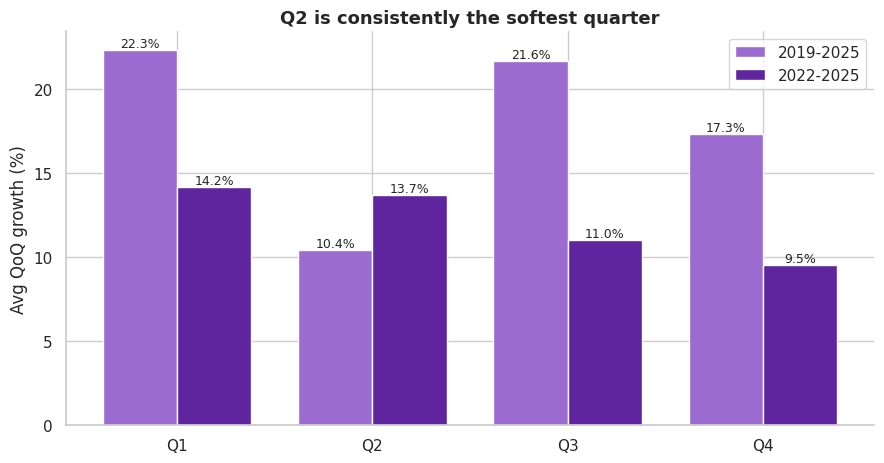

In [25]:
# Chart - 12 visualization code
sea = nat_q[nat_q.year.between(2019, 2025)].groupby("quarter").qoq_pct.mean()
sea_recent = nat_q[nat_q.year.between(2022, 2025)].groupby("quarter").qoq_pct.mean()
x = np.arange(4); w = 0.38
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(x - w/2, sea.values, w, color=LILAC, label="2019-2025")
ax.bar(x + w/2, sea_recent.values, w, color=VIOLET, label="2022-2025")
for i, (a, b) in enumerate(zip(sea.values, sea_recent.values)):
    ax.text(i - w/2, a, f"{a:.1f}%", ha="center", va="bottom", fontsize=9); ax.text(i + w/2, b, f"{b:.1f}%", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, [f"Q{q}" for q in sea.index]); ax.set(ylabel="Avg QoQ growth (%)", title="Q2 is consistently the softest quarter"); ax.legend()
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Grouped bars compare two time windows, which guards against the early hyper-growth years distorting the seasonal pattern.

##### 2. What is/are the insight(s) found from the chart?

Q2 has the lowest average growth in both windows (**10.4%** over 2019-2025 and **13.7%** over 2022-2025), versus **14.2%**, **11.0%** and **9.5%** for the other quarters in 2022-2025. The 2020 lockdown contributes to the longer window.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** Q2 is the natural quarter for promotions and merchant campaigns to smooth demand. **Risk:** only seven yearly observations per quarter and one shock year, so treat the pattern as indicative.

#### Chart - 13  (B - regional share of national transactions by year (category x category))

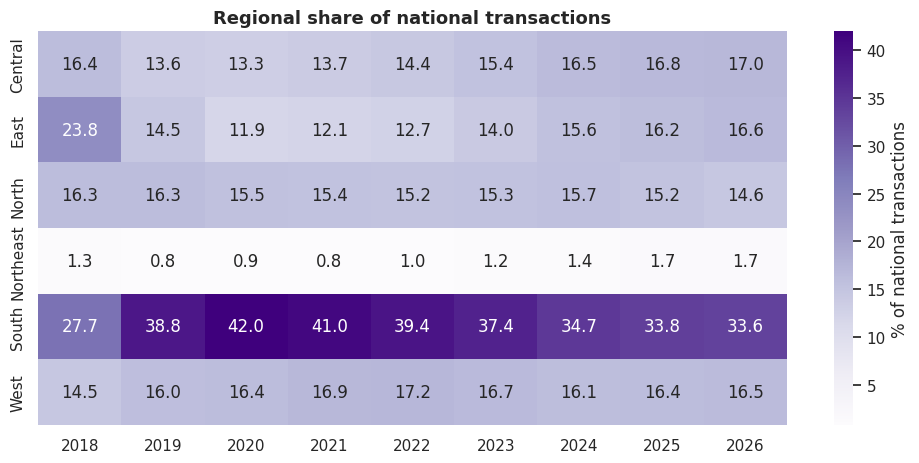

In [26]:
# Chart - 13 visualization code
ry = at.groupby(["year", "region"]).txn_count.sum().unstack()
share = ry.div(ry.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.heatmap(share.T.round(1), annot=True, fmt=".1f", cmap="Purples", cbar_kws={"label": "% of national transactions"}, ax=ax)
ax.set(xlabel="", ylabel="", title="Regional share of national transactions"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A region-by-year heatmap is the right tool for two categorical variables with one measure, and it shows shifts in share rather than absolute growth.

##### 2. What is/are the insight(s) found from the chart?

The South's share rose from **27.7%** (2018) to **42.0%** (2020) and eased to **33.8%** (2025). The East fell from **23.8%** to **11.9%** before recovering to **16.2%**. The Northeast stays at only **1.7%**.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the post-2020 recovery of the East and Central regions shows adoption broadening beyond early South-led markets. **Negative:** the Northeast remains a very small share, pointing to a persistent coverage gap.

#### Chart - 14  (B - payment category mix by region, 2025 (category x category))

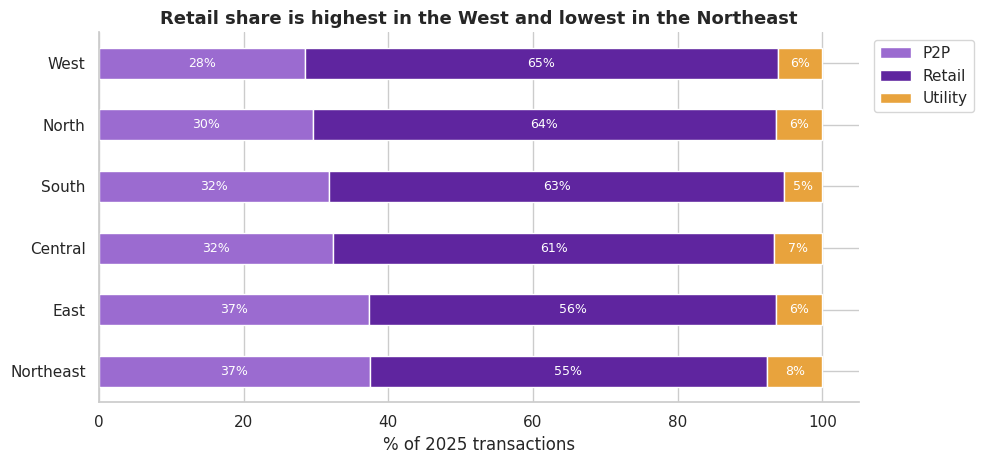

In [27]:
# Chart - 14 visualization code
rc = at[at.year == 2025].groupby(["region", "payment_category"]).txn_count.sum().unstack()
rc = rc.div(rc.sum(axis=1), axis=0) * 100
ax = rc.sort_values("Retail").plot.barh(stacked=True, figsize=(10, 4.8), color=[LILAC, VIOLET, SAFFRON])
for c in ax.containers: ax.bar_label(c, fmt="%.0f%%", label_type="center", color="white", fontsize=9)
ax.set(xlabel="% of 2025 transactions", ylabel="", title="Retail share is highest in the West and lowest in the Northeast"); ax.legend(title="", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A 100% stacked bar compares composition across groups on equal footing, regardless of the region's size.

##### 2. What is/are the insight(s) found from the chart?

Retail is **65.5%** of West transactions but only **55.0%** in the Northeast, where P2P is **37.4%**. Utility payments are highest in the Northeast (**7.6%**).

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** regions with a high P2P share are less developed on the merchant side, so a merchant-acceptance push has the largest headroom there. **Risk:** if acceptance does not follow, the platform stays a transfer tool in those markets.

#### Chart - 15  (B - engagement by region (category x numeric))

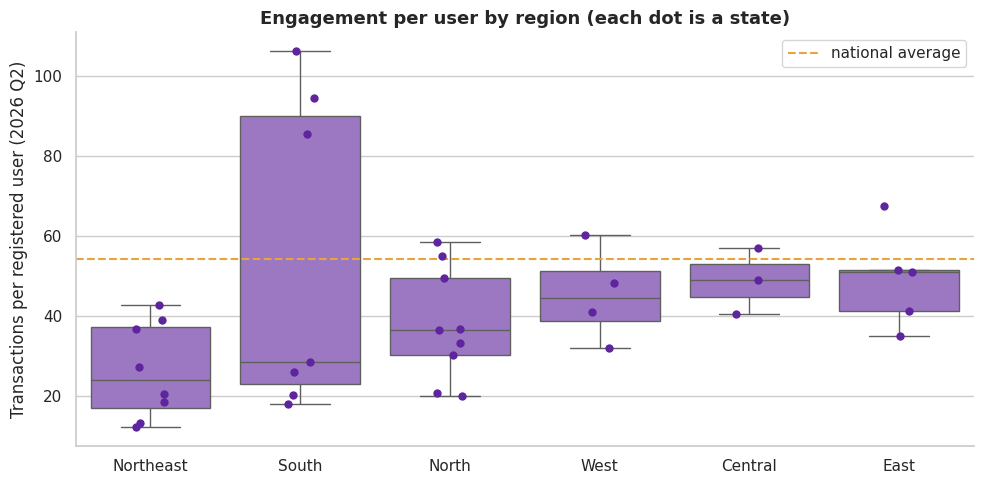

In [28]:
# Chart - 15 visualization code
fig, ax = plt.subplots(figsize=(10, 5))
order = state_latest.groupby("region").txns_per_user.median().sort_values().index
sns.boxplot(data=state_latest, x="region", y="txns_per_user", order=order, color=LILAC, fliersize=0, ax=ax)
sns.stripplot(data=state_latest, x="region", y="txns_per_user", order=order, color=VIOLET, size=6, ax=ax)
ax.axhline(state_latest.txns.sum() / state_latest.users.sum(), color=SAFFRON, ls="--", label="national average")
ax.set(xlabel="", ylabel=f"Transactions per registered user ({LY} Q{LQ})", title="Engagement per user by region (each dot is a state)"); ax.legend()
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A box plot with the individual states overlaid shows both the typical level and the spread inside each region.

##### 2. What is/are the insight(s) found from the chart?

Median engagement is highest in the East (**51**) and Central (**49**) regions and lowest in the Northeast (**24**). The South has the widest spread: **Telangana** at **106** versus **Kerala** at **18**.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** high performers inside each region are proof that higher engagement is achievable locally. **Negative:** the wide South spread shows that regional averages hide real problem states; Kerala needs its own plan rather than a regional one.

#### Chart - 16  (B - three-year growth (CAGR) by state, 2022 to 2025 (category x numeric))

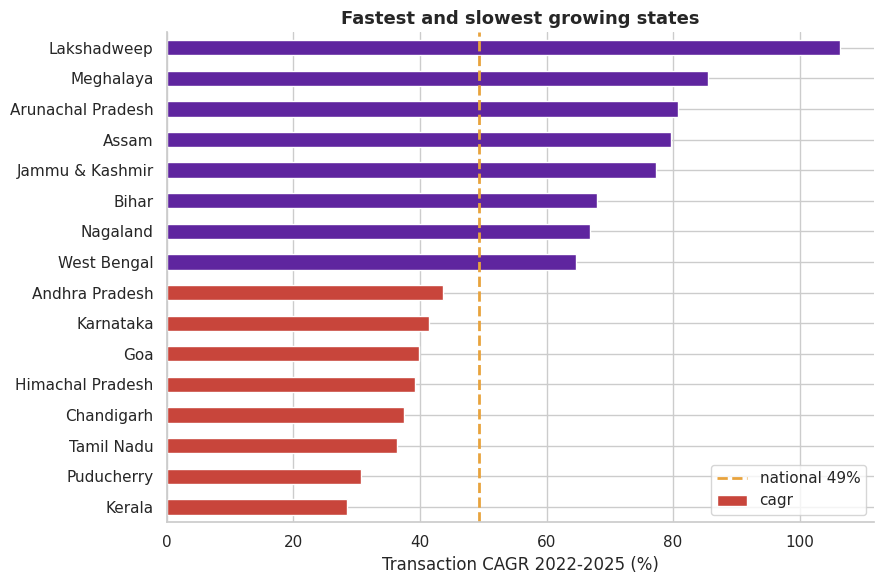

In [29]:
# Chart - 16 visualization code
ys = state_q[state_q.year.isin([2022, 2025])].groupby(["state", "year"]).txns.sum().unstack()
ys["cagr"] = ((ys[2025] / ys[2022]) ** (1 / 3) - 1) * 100
nat_cagr = ((ys[2025].sum() / ys[2022].sum()) ** (1 / 3) - 1) * 100
sel = pd.concat([ys.nsmallest(8, "cagr"), ys.nlargest(8, "cagr")]).sort_values("cagr")
colors = [RED if v < nat_cagr else VIOLET for v in sel.cagr]
ax = sel.cagr.plot.barh(color=colors, figsize=(9, 6))
ax.axvline(nat_cagr, color=SAFFRON, lw=2, ls="--", label=f"national {nat_cagr:.0f}%")
ax.set(xlabel="Transaction CAGR 2022-2025 (%)", ylabel="", title="Fastest and slowest growing states"); ax.legend(); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Compound annual growth removes the effect of base size over a multi-year window, and highlighting the extremes keeps the chart readable.

##### 2. What is/are the insight(s) found from the chart?

National CAGR is **49%**. Lakshadweep grows fastest (**106%**) but from a tiny base; among larger states the leaders are in the Northeast and Jammu & Kashmir. **Kerala** is the slowest of all 36 at **28.5%**, with Puducherry and Tamil Nadu next.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** under-penetrated states are catching up quickly, a sign of a widening market. **Negative:** Kerala and Tamil Nadu are large, mature markets growing far below the national rate; this may indicate saturation or competitor strength and should be investigated before budgets are set.

#### Chart - 17  (B - top 15 districts by transaction value, 2025 (category x numeric))

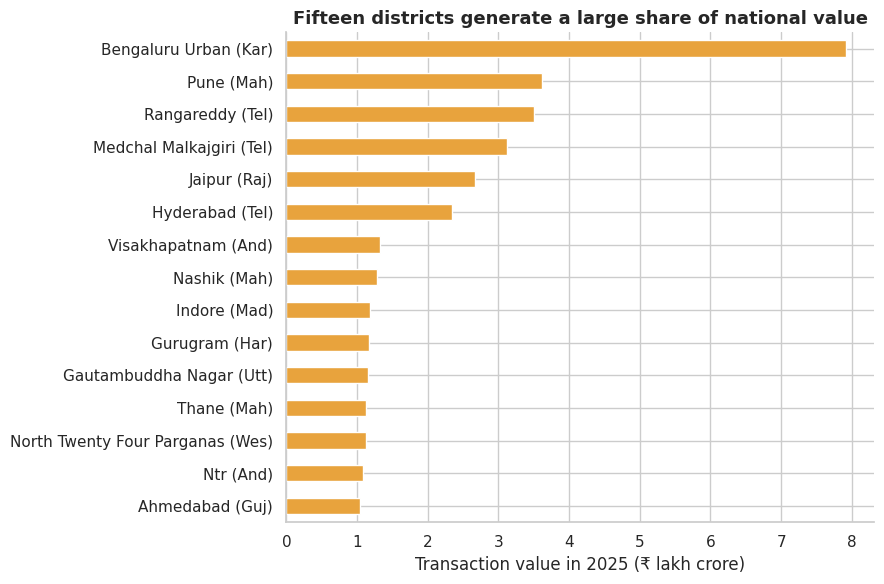

In [30]:
# Chart - 17 visualization code
top = dist.nlargest(15, "amount_cr").sort_values("amount_cr")
labels = top.district + " (" + top.state.str[:3] + ")"
ax = (top.amount_cr / 1e5).plot.barh(color=SAFFRON, figsize=(9, 6)); ax.set_yticklabels(labels)
ax.set(xlabel="Transaction value in 2025 (₹ lakh crore)", ylabel="", title="Fifteen districts generate a large share of national value"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

District-level value is available only in the map tables, and a ranked bar shows exactly where the money concentrates.

##### 2. What is/are the insight(s) found from the chart?

**Bengaluru Urban** leads with about **₹7.9 lakh crore**, more than double the second district. The top 15 districts alone contribute **21.7%** of national value, and most are large metros or the districts around them.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a short list of districts for premium merchant and offers partnerships. **Risk:** value is concentrated in a few metros, so local competition or a regulation change there would have a disproportionate effect.

### Multivariate analysis

#### Chart - 18  (M - engagement x ticket x users by state (bubble chart))

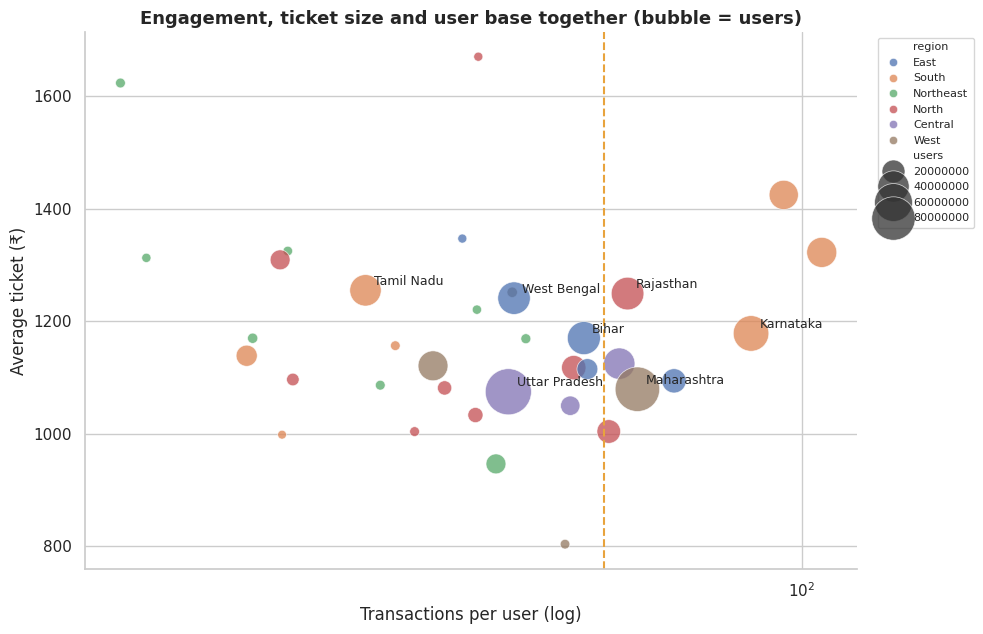

In [31]:
# Chart - 18 visualization code
bub = state_latest.dropna(subset=["users"])
fig, ax = plt.subplots(figsize=(10, 6.5))
sns.scatterplot(data=bub, x="txns_per_user", y="ticket", size="users", sizes=(40, 1100), hue="region", alpha=0.75, ax=ax)
for _, s in bub.nlargest(7, "users").iterrows(): ax.annotate(s.state, (s.txns_per_user, s.ticket), xytext=(6, 4), textcoords="offset points", fontsize=9)
ax.axvline(bub.txns.sum() / bub.users.sum(), color=SAFFRON, ls="--", lw=1.5); ax.set_xscale("log")
ax.set(xlabel="Transactions per user (log)", ylabel="Average ticket (₹)", title="Engagement, ticket size and user base together (bubble = users)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A bubble chart shows four variables at once (engagement, ticket size, user base, region) so states can be classified into quadrants.

##### 2. What is/are the insight(s) found from the chart?

Highest engagement: Telangana (106), Andhra Pradesh (95), Karnataka (85). Lowest: Manipur (12), Mizoram (13), Kerala (18). High engagement does not imply a high ticket, because frequent, small payments dominate the big states while remote states pay rarely but in larger amounts.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the quadrants give different playbooks: grow ticket where frequency is high, grow frequency where ticket is high. **Negative:** large bubbles on the far left are states with many users who rarely transact, the biggest unrealised revenue pool.

#### Chart - 19  (M - district segments (frequency x ticket x region))

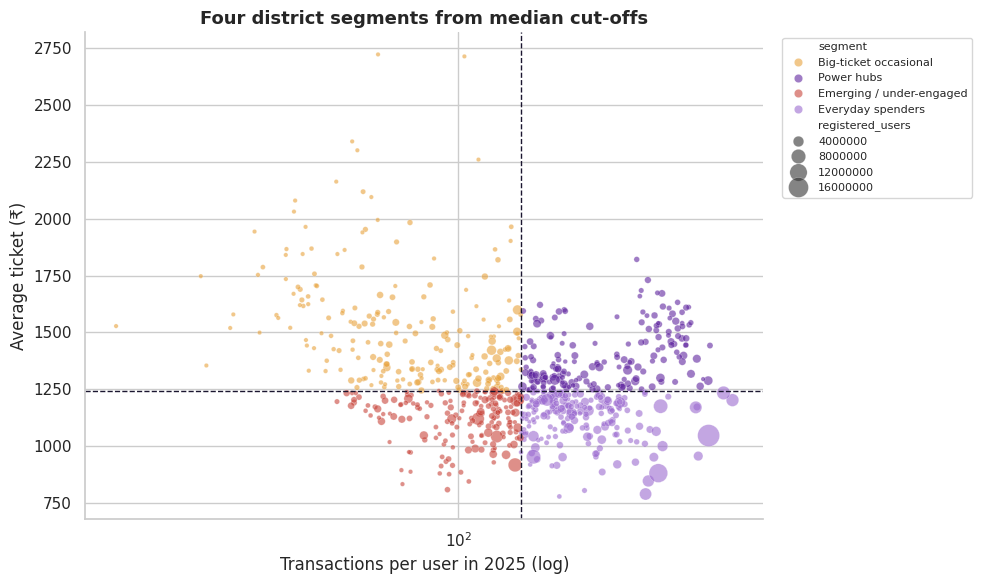

,districts,users_mn,value_share_pct
segment,,,
Big-ticket occasional,210,97.00,8.50
Emerging / under-engaged,181,134.90,10.70
Everyday spenders,210,273.70,45.40
Power hubs,182,171.20,35.40


In [32]:
# Chart - 19 visualization code
fig, ax = plt.subplots(figsize=(10, 6))
pal = {"Power hubs": VIOLET, "Everyday spenders": LILAC, "Big-ticket occasional": SAFFRON, "Emerging / under-engaged": RED}
sns.scatterplot(data=dist, x="txns_per_user", y="ticket", hue="segment", palette=pal, size="registered_users", sizes=(10, 250), alpha=0.6, ax=ax)
ax.axvline(f_med, color=INK, ls="--", lw=1); ax.axhline(t_med, color=INK, ls="--", lw=1); ax.set_xscale("log")
ax.set(xlabel="Transactions per user in 2025 (log)", ylabel="Average ticket (₹)", title="Four district segments from median cut-offs")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8); plt.tight_layout(); plt.show()
display(dist.groupby("segment").agg(districts=("district", "count"), users_mn=("registered_users", lambda x: x.sum() / 1e6),
                                    value_share_pct=("amount", lambda x: 100 * x.sum() / dist.amount.sum())).round(1))

##### 1. Why did you pick the specific chart?

Rule-based segmentation on the two most meaningful behavioural axes gives marketing teams groups they can act on, and a scatter shows how clean the boundaries are.

##### 2. What is/are the insight(s) found from the chart?

Everyday spenders (**210** districts) produce **45.4%** of value and power hubs (**182**) **35.4%**. The **181** emerging districts hold **134.9M** users but generate only **10.7%** of value; big-ticket occasional districts add **8.5%**.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** each segment has a distinct action (retain, upsell, activate, increase frequency). **Negative:** the emerging segment is a drag on average engagement and, if left alone, its accounts may go dormant.

#### Chart - 20  (M - correlation heatmap (district level, Spearman))

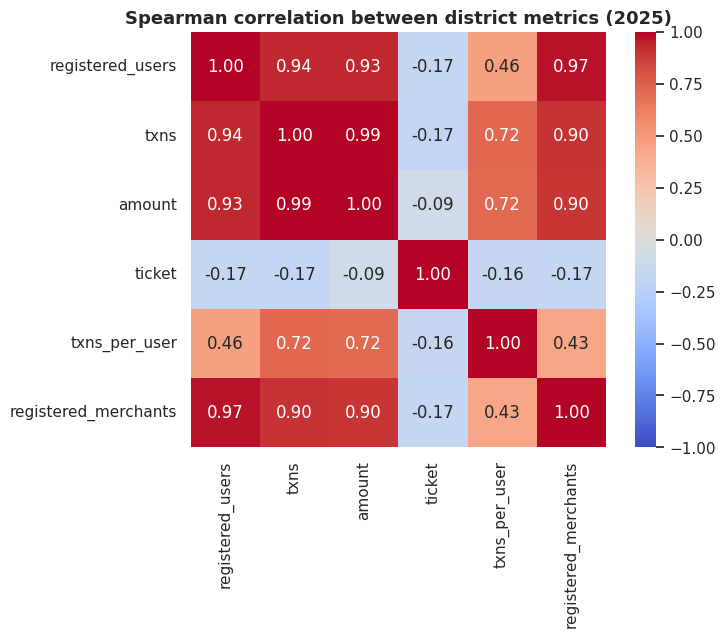

In [33]:
# Chart - 20 visualization code
cols = ["registered_users", "txns", "amount", "ticket", "txns_per_user", "registered_merchants"]
corr = dist[cols].corr(method="spearman")           # rank correlation: robust to the heavy skew
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Spearman correlation between district metrics (2025)"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A correlation matrix summarises every pairwise relationship at once; Spearman is used because Pearson would be dominated by a few giant districts.

##### 2. What is/are the insight(s) found from the chart?

Users, transactions, value and merchants are almost perfectly rank-correlated (users vs transactions **0.94**). Ticket size is only weakly related to volume (**-0.17**), and transactions per user are only moderately related to ticket (**-0.16**).

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** volume is predictable from user counts, but ticket and frequency are independent levers that can be optimised separately. **Caution:** the strong size correlations mean raw totals add little information; use ratios (per user, per merchant) for decisions.

#### Chart - 21  (M - pair plot of district metrics)

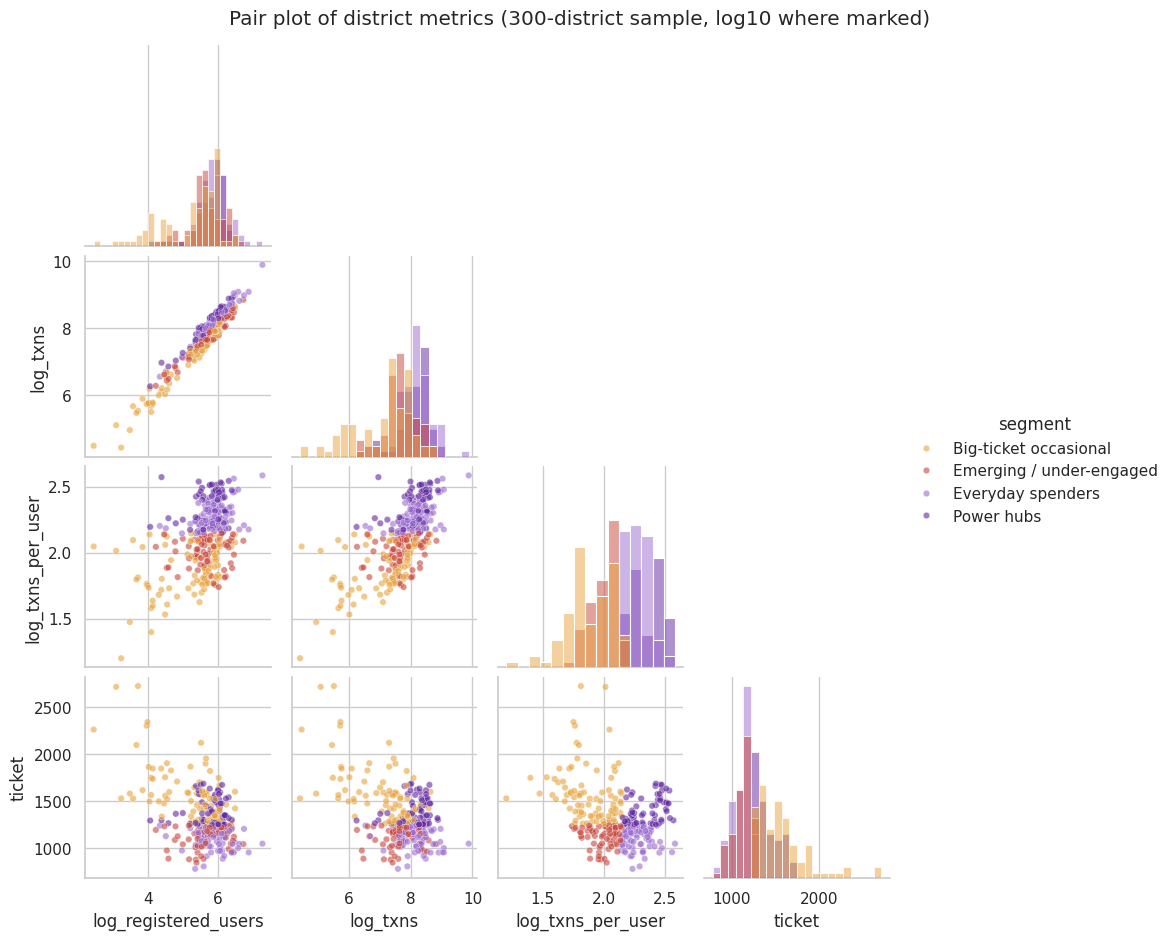

In [34]:
# Chart - 21 visualization code
sample = dist.dropna(subset=["registered_merchants"]).sample(min(300, len(dist)), random_state=42).copy()
for c in ["registered_users", "txns", "txns_per_user"]: sample["log_" + c] = np.log10(sample[c])   # log scale tames skew
g = sns.pairplot(sample, vars=["log_registered_users", "log_txns", "log_txns_per_user", "ticket"], hue="segment",
                 palette=pal, corner=True, plot_kws={"alpha": 0.6, "s": 22}, diag_kind="hist", height=2.3)
g.fig.suptitle("Pair plot of district metrics (300-district sample, log10 where marked)", y=1.02); plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows every bivariate relationship and each variable's distribution together, with colour revealing how segments separate.

##### 2. What is/are the insight(s) found from the chart?

Users vs transactions form a tight straight line (a stable conversion rate), while ticket size scatters with no clear link to size. The segments separate cleanly on the engagement and ticket axes, confirming the median-cut approach.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** validates that the segmentation reflects real structure rather than noise. **Caution:** the plot uses a random 300-district sample for readability; the SQL segment query uses all districts.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?

1. **Activate before acquiring.** The emerging segment has **181** districts and **134.9M** registered users with low engagement. Run activation campaigns (first-bill-pay, merchant cashback) there before spending on new-user acquisition.
2. **Close the merchant gap.** Merchant density ranges from **11** to **89** per 1,000 users. Prioritise merchant onboarding in low-density states, especially where P2P dominates (Northeast, East).
3. **Defend the core and deepen retail.** The top five states carry **52.3%** of volume and retail is **61.9%** of transactions. Focus merchant-side products (QR, soundbox, credit) on the top districts.
4. **Investigate Kerala and Tamil Nadu.** Kerala ranks **36 of 36** on growth (**28.5%** CAGR) and its engagement is **18** transactions per user against **54** nationally. Commission a competitor and user-research study.
5. **Plan around seasonality and maturity.** Schedule campaigns in Q2, the softest quarter, and set targets on revenue per transaction because growth rates are decelerating in every category.
6. **Review anomalies.** Route the SQL anomaly list (districts with ticket sizes more than 3 standard deviations above normal) to risk teams as a *screening* input; the flags are not proof of fraud.
7. **Upsell where ticket size is high.** Remote and high-ticket states are better suited to credit and insurance cross-sell than low-ticket, high-frequency metros.

# **Conclusion**

PhonePe's payment network is large (**128.5B** transactions in 2025), commerce-led and still growing, but growth rates are normalising and value is concentrated in a few states and districts. The most useful lens is not size but engagement: registered users and transactions are almost perfectly correlated, so the differences that matter are in activity per user, merchant density and ticket size. The data supports a clear plan: activate dormant users, grow merchant acceptance in thin markets, protect the metro core, and investigate Kerala. Limitations are that user and merchant counts are cumulative stocks, amounts exist only at district level, and the current Pulse release has no insurance or pin-code data.

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***